# Linked plots: click a point, see the structure

Examples of interactive analysis plots for MD trajectories. Every plot sits next to a 3D viewer of the trajectory,
and clicking a point in the plot shows the matching structure, with the atoms behind that point highlighted. Each
example is a different kind of plot or a different kind of click, so you can pick what fits your own analysis.

**Tools:** MDAnalysis (analysis), plotly `FigureWidget` (clickable plots), nglview (3D viewer), ipywidgets (layout).

**Example system:** a protein kinase with a bound peptide, ATP and two Mg²⁺ in water.
300 ns, every 1.5 ns (200 frames), PBC already removed; the `.tpr` gives bonds, charges and masses.

| Section | Plots | A click… |
|---|---|---|
| 0 | minimal example | goes to that frame |
| 1 | time series · 2D scatter | goes to that frame and draws the distances |
| 2 | event raster · UpSet plot of networks | shows that bond, or a typical frame of that network |
| 3 | event raster | shows both legs of a water bridge and the water |
| 4 | Ramachandran · free-energy landscape · cluster bars | goes to that frame or the cluster's representative |
| 5 | time series · per-residue bars | goes to that frame, or centers the viewer on that residue |
| 6 | heatmap | steps through frames where that contact is made |

In [4]:
import base64, io, warnings
from collections import Counter
import numpy as np
import MDAnalysis as mda
from MDAnalysis import transformations as trans
from MDAnalysis.lib.distances import distance_array, capped_distance
from scipy.stats import gaussian_kde
import plotly.graph_objects as go
import nglview as nv
import ipywidgets as w
from IPython.display import display
from PIL import Image

warnings.filterwarnings("ignore")
ORANGE = "#EE7733"

PANELS = {}   # cell code -> the plot + viewer it shows, for the snapshot cells at the end

class Panel:
    """A plot and a 3D viewer side by side. The saved output can also hold a PNG of both (made by the snapshot cells
    at the end), which is what GitHub shows, since it can't run widgets; Jupyter and VS Code still show the widgets."""
    def __init__(self, fig, v):
        self.fig, self.v, self.png = fig, v, None
        self.box = w.HBox([fig, v], layout=w.Layout(flex_flow="row wrap"))   # viewer wraps below if narrow
        self.handle = display(self, display_id=True)
        PANELS[get_ipython().user_ns["_ih"][-1]] = self   # re-running a cell replaces its entry

    def _repr_mimebundle_(self, **kwargs):
        data = self.box._repr_mimebundle_(**kwargs)
        if self.png:
            data["image/png"] = self.png
        return data


## Load and fit

Our `.tpr` has no chain letters, so give each molecule one; selections below then read as `chainID B` (peptide),
`chainID A` (kinase), `chainID C` (ATP). Fit every frame on the protein Cα (as an on-the-fly transformation) so the
viewer does not tumble and every frame is in the same orientation.

In [5]:
u = mda.Universe("data/md.tpr", "data/md_full.xtc")
ref = mda.Universe("data/md.tpr", "data/md_full.xtc")
for univ in (u, ref):
    for seg, chain in zip(univ.segments, "ABCXXWII"):
        seg.atoms.chainIDs = chain

ca = "chainID A and name CA"
u.trajectory.add_transformations(trans.fit_rot_trans(u.select_atoms(ca), ref.select_atoms(ca)))
frames = np.arange(u.trajectory.n_frames)
t_ns = np.array([ts.time for ts in u.trajectory]) / 1000
print(u.atoms.n_atoms, "atoms,", len(frames), "frames,", t_ns[1] - t_ns[0], "ns apart")

47958 atoms, 200 frames, 1.5 ns apart


## 0. The minimal example 

The whole idea in a few lines: a viewer, a `FigureWidget` whose points carry their frame number in `customdata`, and
an `on_click` callback that sets the viewer's frame. Here: distance between the peptide and kinase centers of mass.
Everything after this is the same pattern plus styling and highlighting.

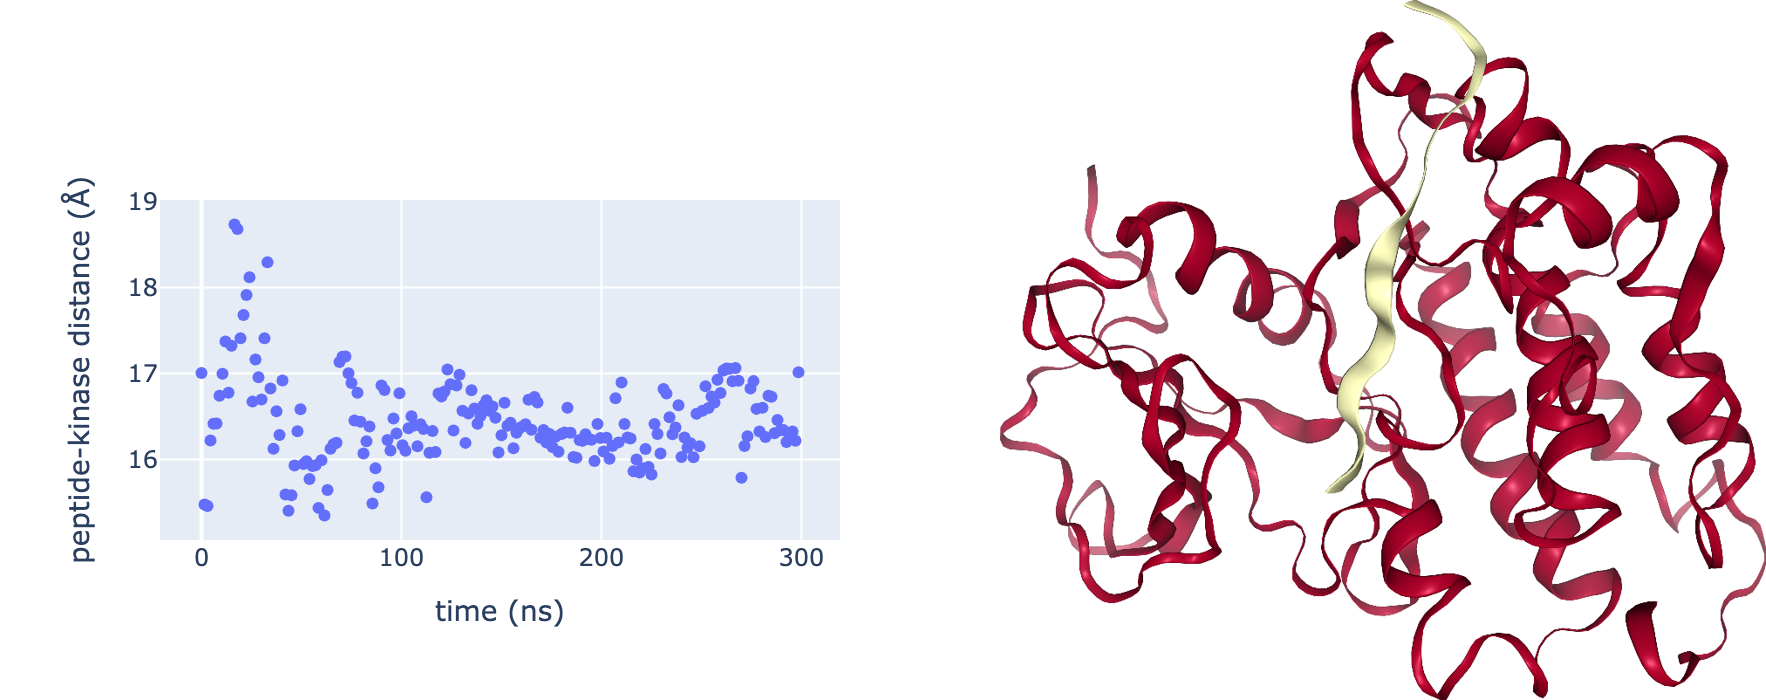

In [6]:
d = [np.linalg.norm(u.select_atoms("chainID B").center_of_mass() - u.select_atoms("chainID A").center_of_mass())
     for ts in u.trajectory]

view0 = nv.show_mdanalysis(u.select_atoms("chainID A B C"), default=False)
view0.add_cartoon()
view0.center()
view0.layout.width, view0.layout.height = "420px", "350px"
plot0 = go.FigureWidget(go.Scatter(x=t_ns, y=d, mode="markers", customdata=frames))
plot0.data[0].on_click(lambda trace, points, state: setattr(view0, "frame", int(trace.customdata[points.point_inds[0]])))
plot0.update_layout(width=500, height=350, xaxis_title="time (ns)", yaxis_title="peptide-kinase distance (Å)")
panel0 = Panel(plot0, view0)   # w.HBox([plot0, view0]), plus a PNG for GitHub (see the setup cell)

## Helpers

**Labels** for plot axes (specific to this system): peptide residues by position from the substrate Tyr (P0, P-1,
P+1, …), kinase residues by their sequence number.

In [7]:
P0, SRC_OFFSET = 285, 254          # P0 Tyr residue number; Src number = kinase resid + 254

def label(res):
    """'P-1 His', 'Asp386', 'ATP', 'Mg', 'water'."""
    name = {"HIE": "His", "HID": "His"}.get(res.resname, res.resname.title())
    chain = res.atoms[0].chainID
    if chain == "B":
        return f"P{res.resid - P0:+d} {name}".replace("+0", "0").replace("-", "-")
    if chain == "A":
        return f"{name}{res.resid + SRC_OFFSET}"
    return {"ATP": "ATP", "MG": "Mg"}.get(res.resname, "water")

**Viewer style:** kinase white and half transparent, peptide orange, active-site side chains as sticks, Mg²⁺ green.
The purple balls are the backbone atoms used in section 4. `show` jumps to a frame and draws atom pairs as dashed
lines with their distance (they follow the trajectory if you press play); calling it again replaces the highlight.

**Camera:** to reuse a view, rotate the viewer by hand and read `v._camera_orientation`; paste that list in as
`ORIENT`.

In [8]:
solute = u.select_atoms("not chainID W I")
with_water = u.select_atoms("not chainID I")                       # solute + bulk water
assert (with_water.indices == np.arange(with_water.n_atoms)).all()  # viewer atom @i = MDAnalysis atom i
DPCA_ATOMS = "(283:B and .C) or (284-288:B and (.N or .CA or .C)) or (289:B and .N)"   # φ/ψ atoms of P-1...P+3
SITE = ("(((284 or 285) and :B) or ((41 or 132 or 134 or 137 or 150) and :A and sidechainAttached)"
        " or :C or (:X and not MG)) and not hydrogen")

cam = np.array([0.066919, 0.67928, 0.73082, 146.38,     
                0.9807, -0.17964, 0.07717, 73.594,
                0.1837, 0.71155, -0.67819, -45.094]).reshape(3, 4)
R, eye = cam[:, :3], cam[:, 3]
center = ref.select_atoms("(chainID B and resid 284 285) or chainID C").center_of_geometry()
dist = (eye - center) @ R[:, 2]
M = np.eye(4)
M[:3, :3] = np.diag([-1, 1, -1]) @ R.T * dist   # NGL's camera sits on -z looking toward +z
M[:3, 3] = -center                             # NGL shifts by -center before rotating
ORIENT = M.T.ravel().tolist()      # nglview wants the 4x4 matrix column by column

def viewer(atoms=solute):
    """A new 3D viewer of the trajectory with this tutorial's style and camera."""
    v = nv.show_mdanalysis(atoms, default=False)
    v.add_cartoon(":A", color="white", opacity=0.5)
    v.add_cartoon(":B", color=ORANGE)
    v.add_licorice(SITE)
    v.add_spacefill("MG", radiusScale=0.6, color="green")
    v.add_ball_and_stick(DPCA_ATOMS, color="#AA3377", radiusScale=1.5)
    v.parameters = {"cameraFov": 30}
    v._set_camera_orientation(ORIENT)
    v.layout.width, v.layout.height = "420px", "400px"
    return v

def show(v, frame, pairs=()):
    """Go to a frame; draw each (atom, atom) index pair as a dashed line with its distance, residues as sticks."""
    v.frame = int(frame)
    for name in ("sticks", "distances"):   # one name each: nglview skips the next match after a removal
        v._remove_representations_by_name(name)
    if len(pairs):
        res = u.atoms[np.unique(pairs)].residues.atoms.select_atoms("not name H*")
        v.add_licorice("@" + ",".join(map(str, res.indices)), name="sticks")
        v.add_distance(atomPair=[[f"@{a}", f"@{b}"] for a, b in pairs], color="black", labelColor="black",
                       name="distances")

viewer()

NGLWidget(layout=Layout(height='400px', width='420px'), max_frame=199)

**Linking a plot to the viewer:** `linked(fig)` puts a plot next to a new viewer. Each point carries a number in
`customdata`; clicking sets the viewer's frame to it. With `hits`, a list of (frame, atom pairs), the number is an
index into `hits` instead, and the pairs are drawn. `mark` shows which point was clicked: a black outline on a
bar, a black ring on anything else. A hit can also be a function that returns (frame, pairs), so
repeated clicks can step through frames. `raster` turns (frame, label, atom pairs) events into an event plot plus
its `hits`.

In [9]:
def mark(fig, trace, i):
    """Mark the clicked point on the plot: outline a bar, ring anything else."""
    with fig.batch_update():
        for t in fig.data:
            if t.type == "bar":
                t.marker.line = dict(color="black", width=[3 if t.uid == trace.uid and j == i else 0
                                                           for j in range(len(t.x))])
            if t.name == "clicked":
                t.update(x=[] if trace.type == "bar" else [trace.x[i]], y=[] if trace.type == "bar" else [trace.y[i]],
                         xaxis=trace.xaxis, yaxis=trace.yaxis)

def linked(fig, hits=None, atoms=solute):
    """Show a plot next to a viewer; clicking a point shows its frame (and its atom pairs, with hits).
    A hit can also be a function returning (frame, pairs), called on every click."""
    v, fig = viewer(atoms), go.FigureWidget(fig)
    def click(trace, points, state):
        if points.point_inds:
            mark(fig, trace, points.point_inds[0])
            c = int(np.ravel(trace.customdata[points.point_inds[0]])[0])
            h = hits[c] if hits is not None else (c,)
            show(v, *(h() if callable(h) else h))
    for trace in fig.data:
        if trace.customdata is not None:
            trace.on_click(click)
    fig.add_scatter(x=[], y=[], name="clicked", mode="markers", hoverinfo="skip", showlegend=False,
                    marker=dict(symbol="circle-open", size=16, color="black", line_width=2))
    if hits is not None:
        show(v, *(hits[0]() if callable(hits[0]) else hits[0]))
    fig.update_layout(width=520, height=400, template="simple_white", showlegend=False, margin=dict(l=60, r=20, t=30, b=50))
    Panel(fig, v)

def raster(events):
    """Event plot from (frame, label, atom pairs) events; returns the figure and its hits for linked()."""
    f, lab, pairs = map(list, zip(*events))
    rows = sorted(set(lab), key=lab.count)
    fig = go.Figure(go.Scatter(x=t_ns[f], y=lab, mode="markers", customdata=np.arange(len(f)),
                               marker=dict(symbol="line-ns-open", size=9, color=ORANGE),
                               hovertemplate="%{y}, %{x:.0f} ns<extra></extra>"))
    fig.update_layout(xaxis_title="time (ns)", yaxis=dict(categoryorder="array", categoryarray=rows))
    return fig, list(zip(f, pairs))

## 1. Distances

**Example metric:** distance from the substrate Tyr hydroxyl to the catalytic Asp and to the ATP γ-phosphorus
(both short = ready to react).

**Time series:** click any point to go to that frame; the Tyr-Asp distance is drawn in the viewer.

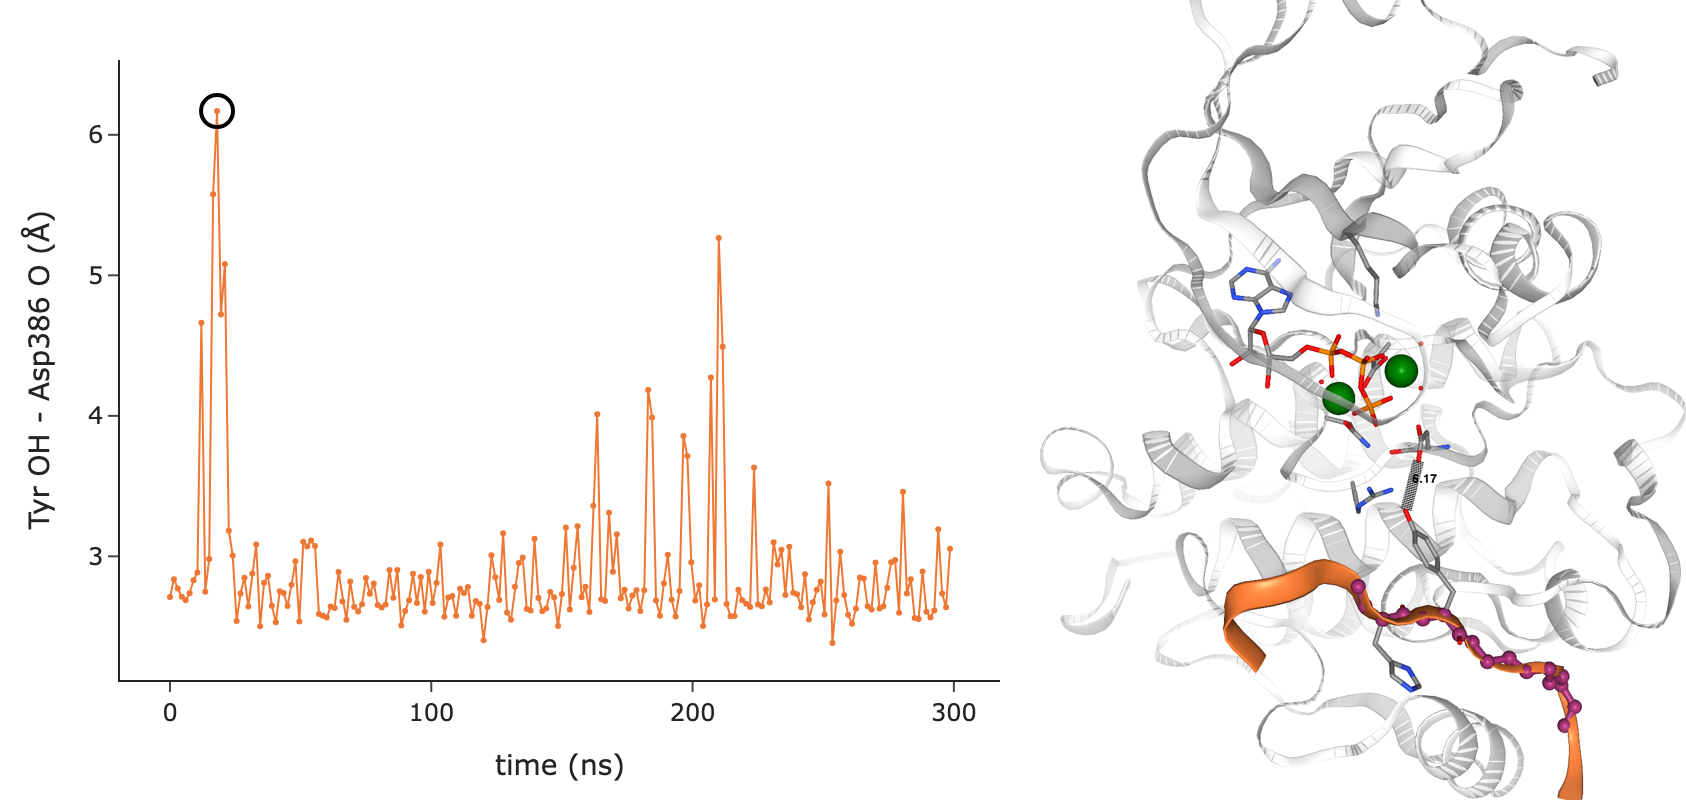

In [10]:
tyr_oh = u.select_atoms("chainID B and resid 285 and name OH")
asp_o = u.select_atoms("chainID A and resid 132 and name OD1 OD2")
pg = u.select_atoms("chainID C and name PG")
d_asp, d_pg, asp_line, lines = [], [], [], []
for f, ts in enumerate(u.trajectory):
    d = distance_array(tyr_oh.positions, asp_o.positions)[0]
    d_asp.append(d.min())
    d_pg.append(distance_array(tyr_oh.positions, pg.positions).min())
    asp, pg_pair = (tyr_oh[0].index, asp_o[d.argmin()].index), (tyr_oh[0].index, pg[0].index)
    asp_line.append((f, [asp]))
    lines.append((f, [asp, pg_pair]))
d_asp, d_pg = np.array(d_asp), np.array(d_pg)        # customdata = frame = index into asp_line / lines

linked(go.Figure(go.Scatter(x=t_ns, y=d_asp, mode="lines+markers", customdata=frames,
                            marker=dict(size=3, color=ORANGE), line=dict(width=1, color=ORANGE)))
       .update_layout(xaxis_title="time (ns)", yaxis_title="Tyr OH - Asp386 O (Å)"), asp_line)

**2D scatter, colored by time:** two distances at once. Clusters of points are arrangements the system keeps
returning to; click into each to compare them. Both distances are drawn.

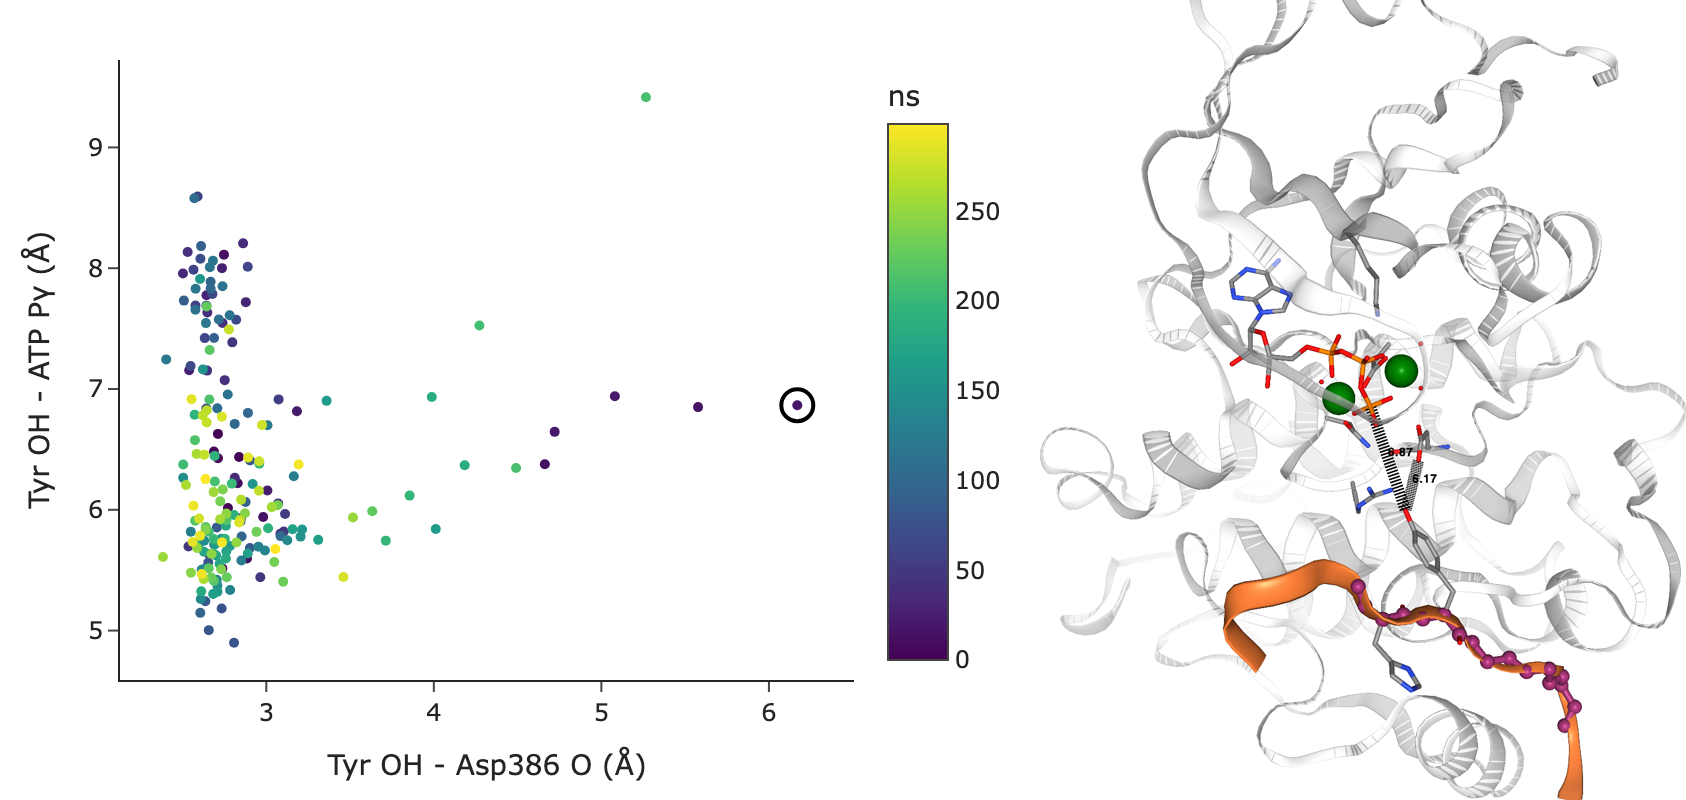

In [11]:
linked(go.Figure(go.Scatter(x=d_asp, y=d_pg, mode="markers", customdata=frames,
                            marker=dict(size=5, color=t_ns, colorscale="Viridis", colorbar=dict(title="ns")),
                            hovertemplate="%{x:.1f}, %{y:.1f} Å<extra></extra>"))
       .update_layout(xaxis_title="Tyr OH - Asp386 O (Å)", yaxis_title="Tyr OH - ATP Pγ (Å)"), lines)

## 2. Hydrogen bonds

**Example metric:** hydrogen bonds between the peptide and the kinase or ATP, with MDAnalysis
`HydrogenBondAnalysis` defaults (donor-acceptor ≤ 3.0 Å, donor-H-acceptor ≥ 150°). Donors, hydrogens and acceptors
are guessed from the `.tpr` charges and masses. If your run uses hydrogen mass repartitioning, hydrogens weigh about
3 Da, so `guess_hydrogens` needs `max_mass=4` or it finds none.

In [12]:
from MDAnalysis.analysis.hydrogenbonds import HydrogenBondAnalysis

hba = HydrogenBondAnalysis(u, between=["chainID B", "chainID A or chainID C"], update_selections=False)
hba.hydrogens_sel = hba.guess_hydrogens("chainID A B C", max_mass=4)
hba.acceptors_sel = hba.guess_acceptors("chainID A B C")
hba.run()

hbond = lambda d, a: f"{label(u.atoms[d].residue)} {u.atoms[d].name} → {label(u.atoms[a].residue)} {u.atoms[a].name}"
events = [(int(f), hbond(int(d), int(a)), [(int(d), int(a))]) for f, d, h, a, *_ in hba.results.hbonds]
hb_dist = {(int(f), hbond(int(d), int(a))): dist for f, d, h, a, dist, angle in hba.results.hbonds}   # D-A (Å)
count = Counter(p for _, p, _ in events)
events = [e for e in events if count[e[1]] > 0.05 * len(frames)]           # bonds present > 5% of the time
print(len(count), "different hydrogen bonds,", len({e[1] for e in events}), "present more than 5% of the time")

39 different hydrogen bonds, 13 present more than 5% of the time


**Event raster:** one row per bond, a tick in every frame where it is present (rows sorted by how often). Good for
many on/off events at once. Click a tick to see that frame with that bond drawn.

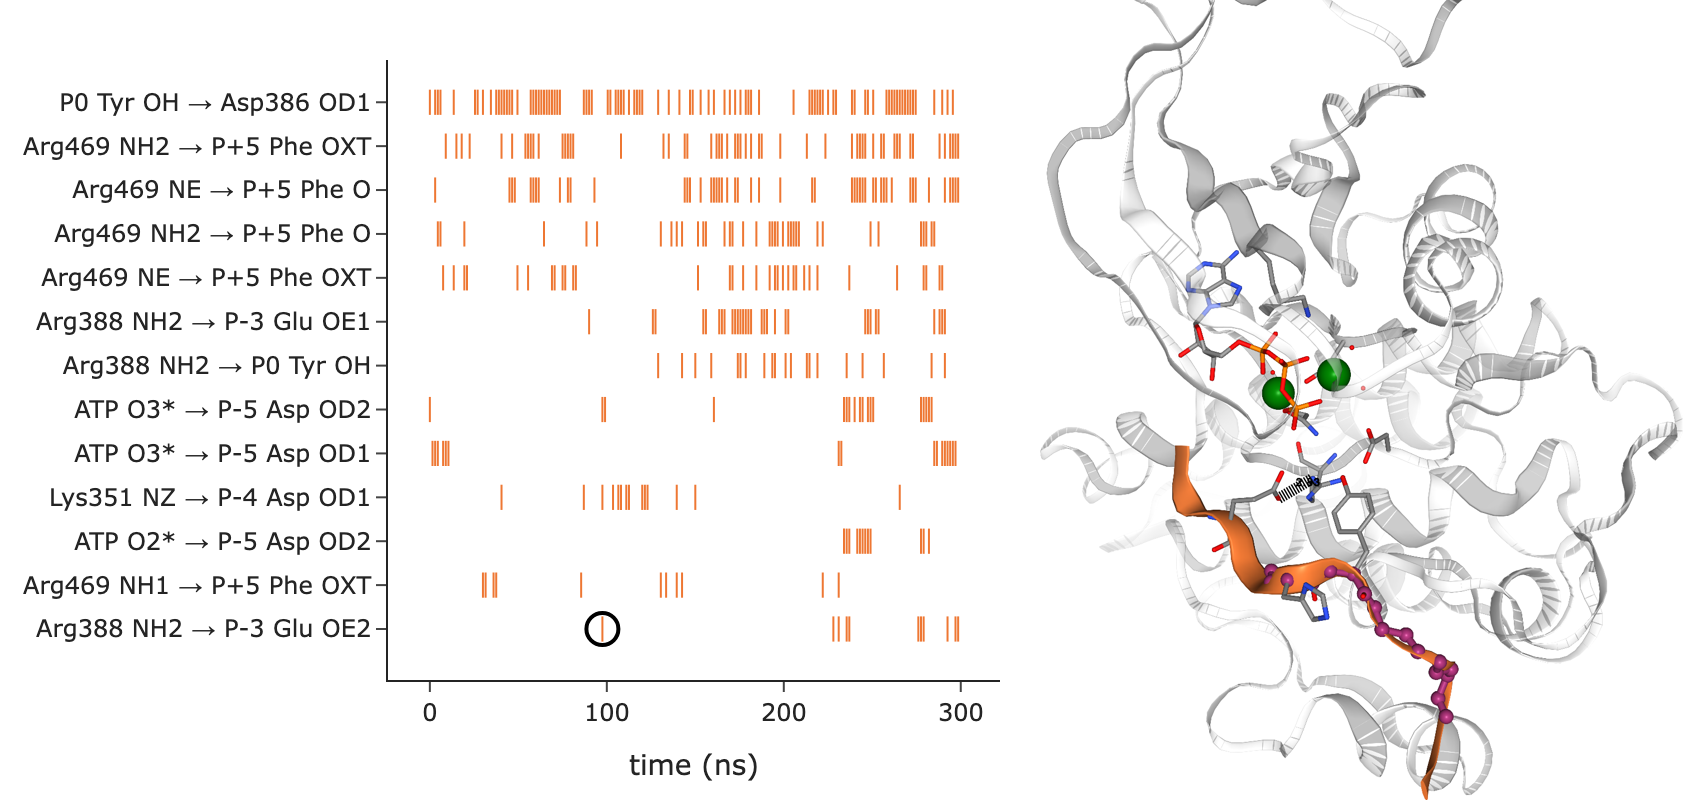

In [13]:
linked(*raster(events))

**Networks:** the set of hydrogen bonds present in a frame is its network. Bars: how often each network occurs;
dots underneath: which bonds it contains (an UpSet plot). Click a bar or dot to see a typical frame of that network
(each bond's distance closest to its median over the network's frames).

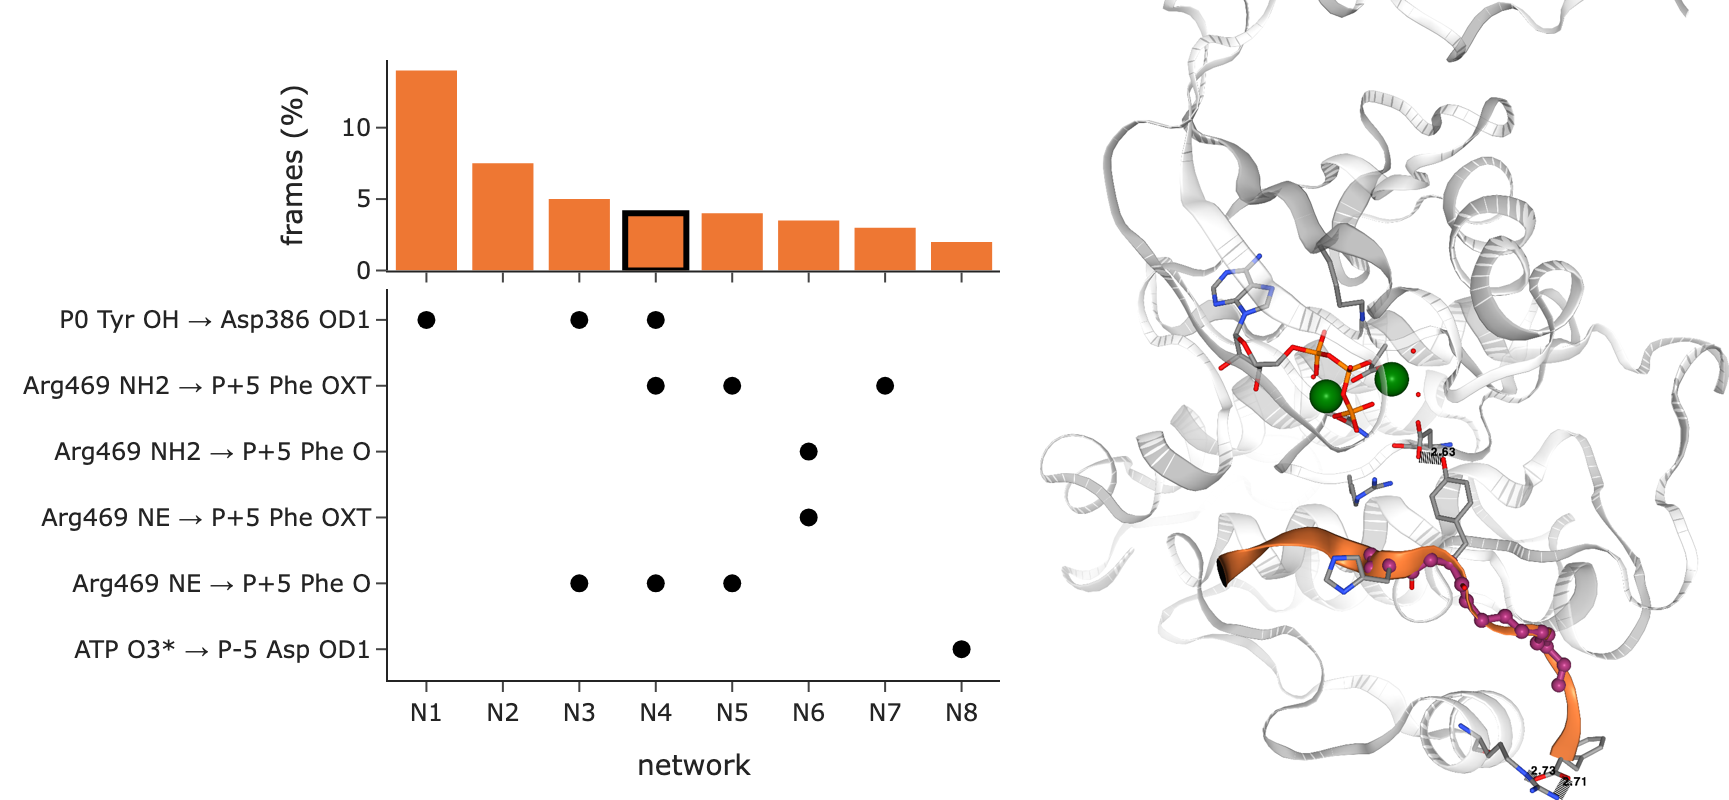

In [14]:
from plotly.subplots import make_subplots

network, pairs_at = {f: frozenset() for f in frames}, {}
for f, p, pairs in events:
    network[f] |= {p}
    pairs_at.setdefault(f, []).extend(pairs)
top = Counter(network.values()).most_common(8)

def typical(fs, bonds):
    """The frame in fs whose bond distances are closest to each bond's median over fs."""
    if not bonds:
        return fs[len(fs) // 2]
    D = np.array([[hb_dist[f, b] for b in bonds] for f in fs])
    return fs[np.abs(D - np.median(D, axis=0)).sum(axis=1).argmin()]

members = [sorted(f for f, n in network.items() if n == net) for net, _ in top]
hits = [(f, pairs_at.get(f, [])) for f in (typical(fs, sorted(net)) for fs, (net, _) in zip(members, top))]
names = [f"N{i + 1}" for i in range(len(top))]
dots = [(names[i], b, i) for i, (net, _) in enumerate(top) for b in net]

fig = make_subplots(rows=2, cols=1, shared_xaxes=True, row_heights=[0.35, 0.65], vertical_spacing=0.03)
fig.add_trace(go.Bar(x=names, y=[100 * c / len(frames) for _, c in top], customdata=np.arange(len(top)),
                     marker_color=ORANGE, hovertemplate="%{y:.0f}% of frames<extra></extra>"), 1, 1)
fig.add_trace(go.Scatter(x=[d[0] for d in dots], y=[d[1] for d in dots], customdata=[d[2] for d in dots],
                         mode="markers", marker=dict(size=9, color="black"), hoverinfo="skip"), 2, 1)
fig.update_yaxes(title_text="frames (%)", row=1, col=1)
fig.update_yaxes(categoryorder="array", categoryarray=sorted({d[1] for d in dots}), automargin=True, row=2, col=1)
fig.update_xaxes(title_text="network", row=2, col=1)
fig.update_layout(showlegend=False)
linked(fig, hits)

## 3. Water bridges

**Example metric:** a water hydrogen-bonded to both the peptide and the kinase or ATP (`WaterBridgeAnalysis`, one
water, default cutoffs). It takes a little longer to compute, so only using every 10th frame here. Same raster as above; a click draws both hydrogen bonds and shows the bridging water. Only this viewer loads the bulk water
(`atoms=with_water`), and it draws a water only when it is highlighted.

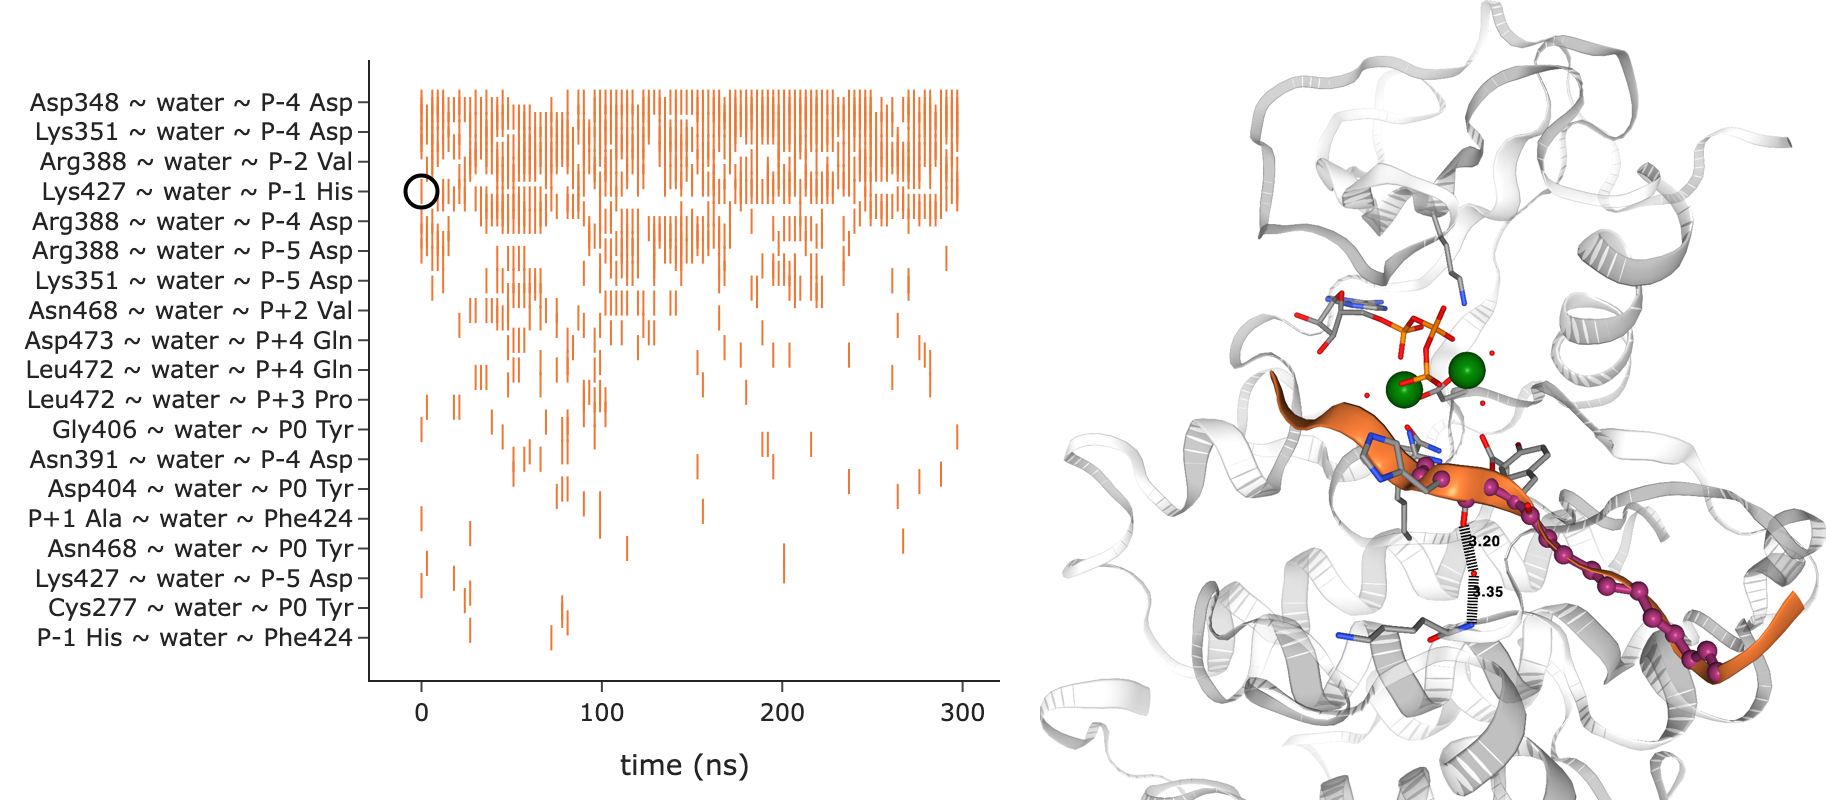

In [15]:
from MDAnalysis.analysis.hydrogenbonds import WaterBridgeAnalysis

STEP = 2
wba = WaterBridgeAnalysis(u, "chainID B", "chainID A or chainID C", water_selection="chainID W X", order=1)
wba.run(step=STEP)

heavy = lambda hb: (hb[0], hb[3]) if hb[1] is None else (hb[1], hb[2])   # keys: (H, D, A, ...) or (A, None, H, D, ...)
events = []                         # network: {peptide-water H-bond: {water-partner H-bond: None}}; direct bonds -> None
for i, net in enumerate(wba.results.network):
    for first, second in net.items():
        for nxt in (second or {}):
            atoms = [x for x in first[:3] + nxt[:3] if x is not None]
            ends = sorted({label(u.atoms[x].residue) for x in atoms} - {"water"})
            if len(ends) == 2:
                events.append((i * STEP, " ~ water ~ ".join(ends), [heavy(first), heavy(nxt)]))
events = list({(f, lab): (f, lab, pairs) for f, lab, pairs in events}.values())    # one per bridge per frame
linked(*raster(events), atoms=with_water)

## 4. Conformation of a flexible region

**Ramachandran plot:** backbone φ/ψ of one residue (the substrate Tyr) in every frame, colored by time. Click a point
to see that conformation.

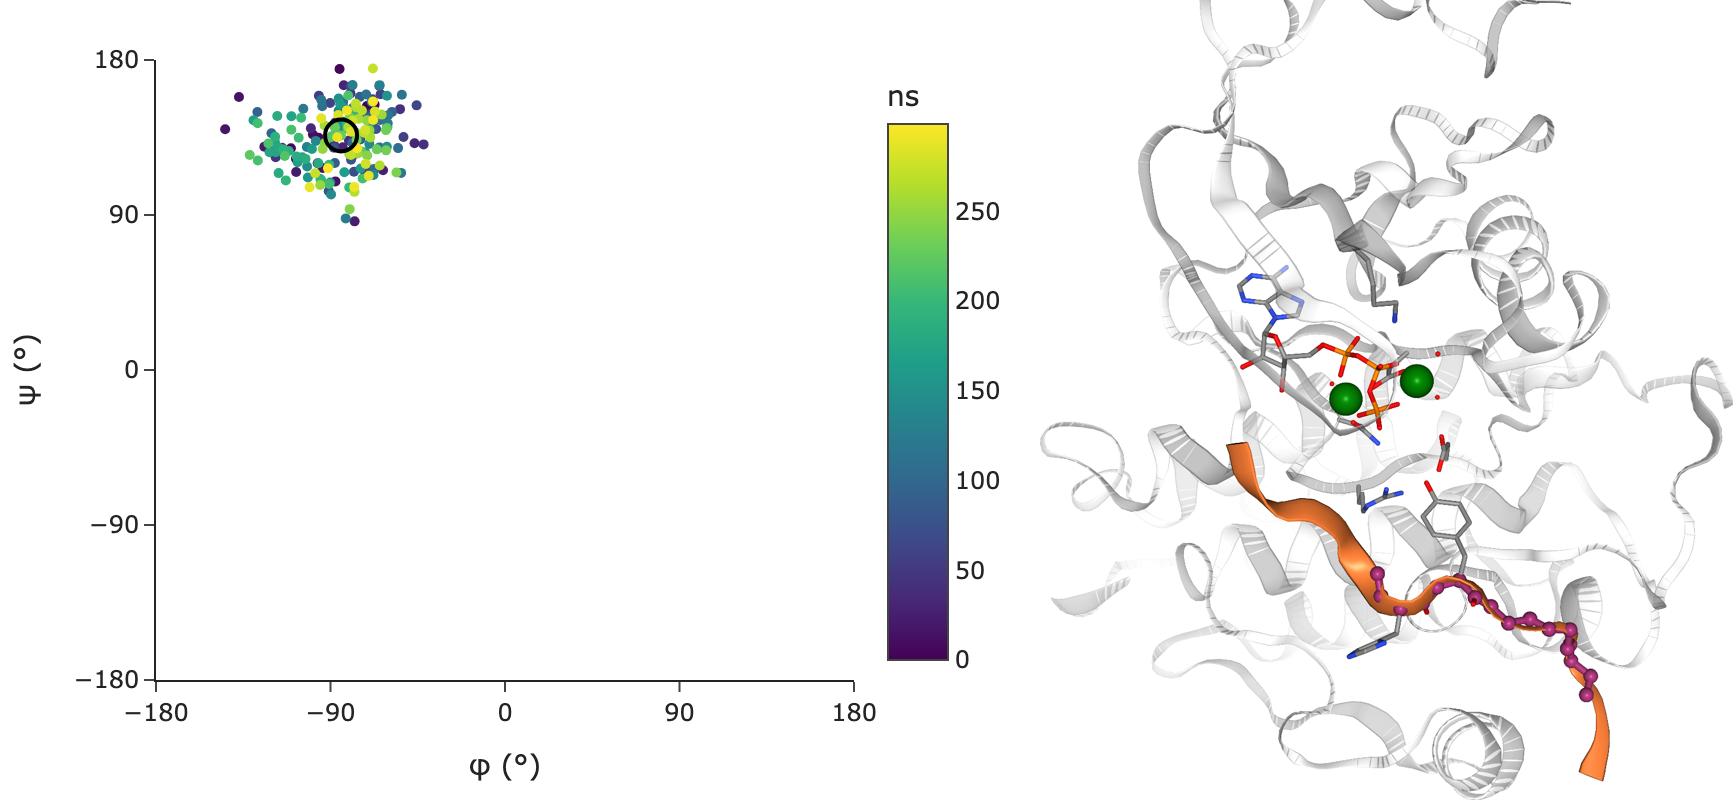

In [16]:
from MDAnalysis.analysis.dihedrals import Ramachandran

rama = Ramachandran(u.select_atoms("chainID B and resid 284:288")).run()    # P-1...P+3
phi, psi = rama.results.angles[:, 1, 0], rama.results.angles[:, 1, 1]      # second residue = P0

linked(go.Figure(go.Scatter(x=phi, y=psi, mode="markers", customdata=frames,
                            marker=dict(size=5, color=t_ns, colorscale="Viridis", colorbar=dict(title="ns")),
                            hovertemplate="φ %{x:.0f}°, ψ %{y:.0f}°<extra></extra>"))
       .update_layout(xaxis=dict(title="φ (°)", range=[-180, 180], dtick=90),
                      yaxis=dict(title="ψ (°)", range=[-180, 180], dtick=90)))

**Free-energy landscape (dihedral PCA):** φ/ψ of five peptide residues around the Tyr (the purple atoms) → cos/sin
(removes the ±180° jump) → PCA → first two components. Background: free energy –ln p (kT) from a kernel density
estimate. Click points in different basins to compare them.

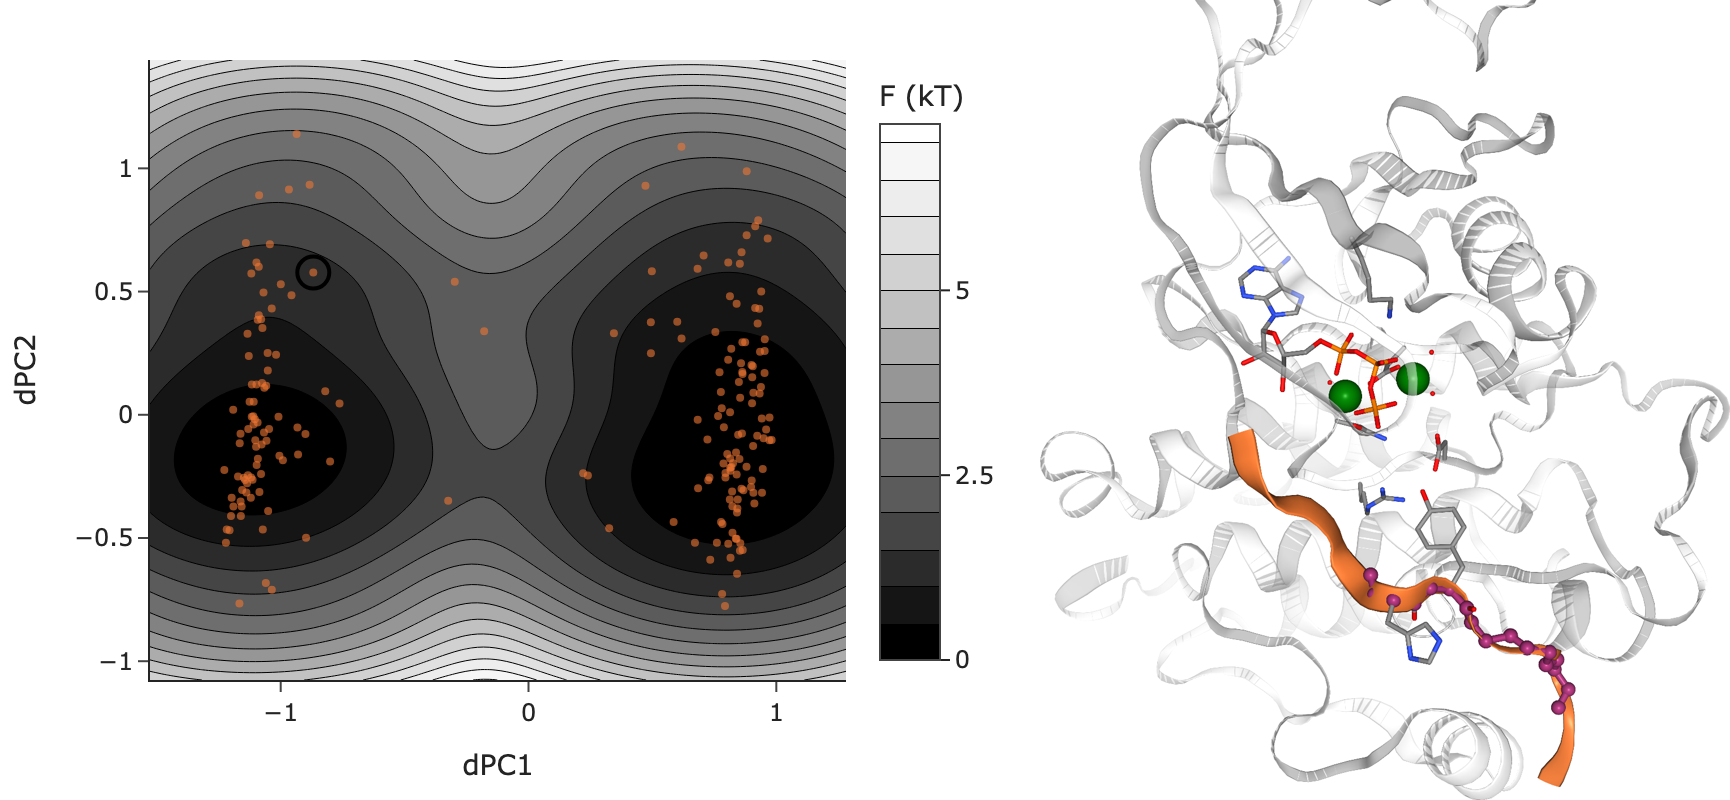

In [17]:
from sklearn.decomposition import PCA

ang = np.deg2rad(rama.results.angles.reshape(len(frames), -1))
pc = PCA(n_components=4).fit_transform(np.hstack([np.cos(ang), np.sin(ang)]))

g1, g2 = (np.linspace(v.min() - 0.3, v.max() + 0.3, 120) for v in pc[:, :2].T)
G1, G2 = np.meshgrid(g1, g2)
F = -np.log(gaussian_kde(pc[:, :2].T)(np.vstack([G1.ravel(), G2.ravel()])).reshape(G1.shape))
F -= F.min()

linked(go.Figure([
    go.Contour(x=g1, y=g2, z=np.clip(F, 0, 8), colorscale="Greys_r", ncontours=16,
               colorbar=dict(title="F (kT)"), hoverinfo="skip"),
    go.Scatter(x=pc[:, 0], y=pc[:, 1], mode="markers", customdata=frames,
               marker=dict(size=4, color=ORANGE, opacity=0.6), hovertemplate="frame %{customdata}<extra></extra>")])
       .update_layout(xaxis_title="dPC1", yaxis_title="dPC2"))

**States:** cluster the frames on the first 4 dihedral PCs (k-means, 4 clusters). Click a bar to see the frame
closest to that cluster's center.

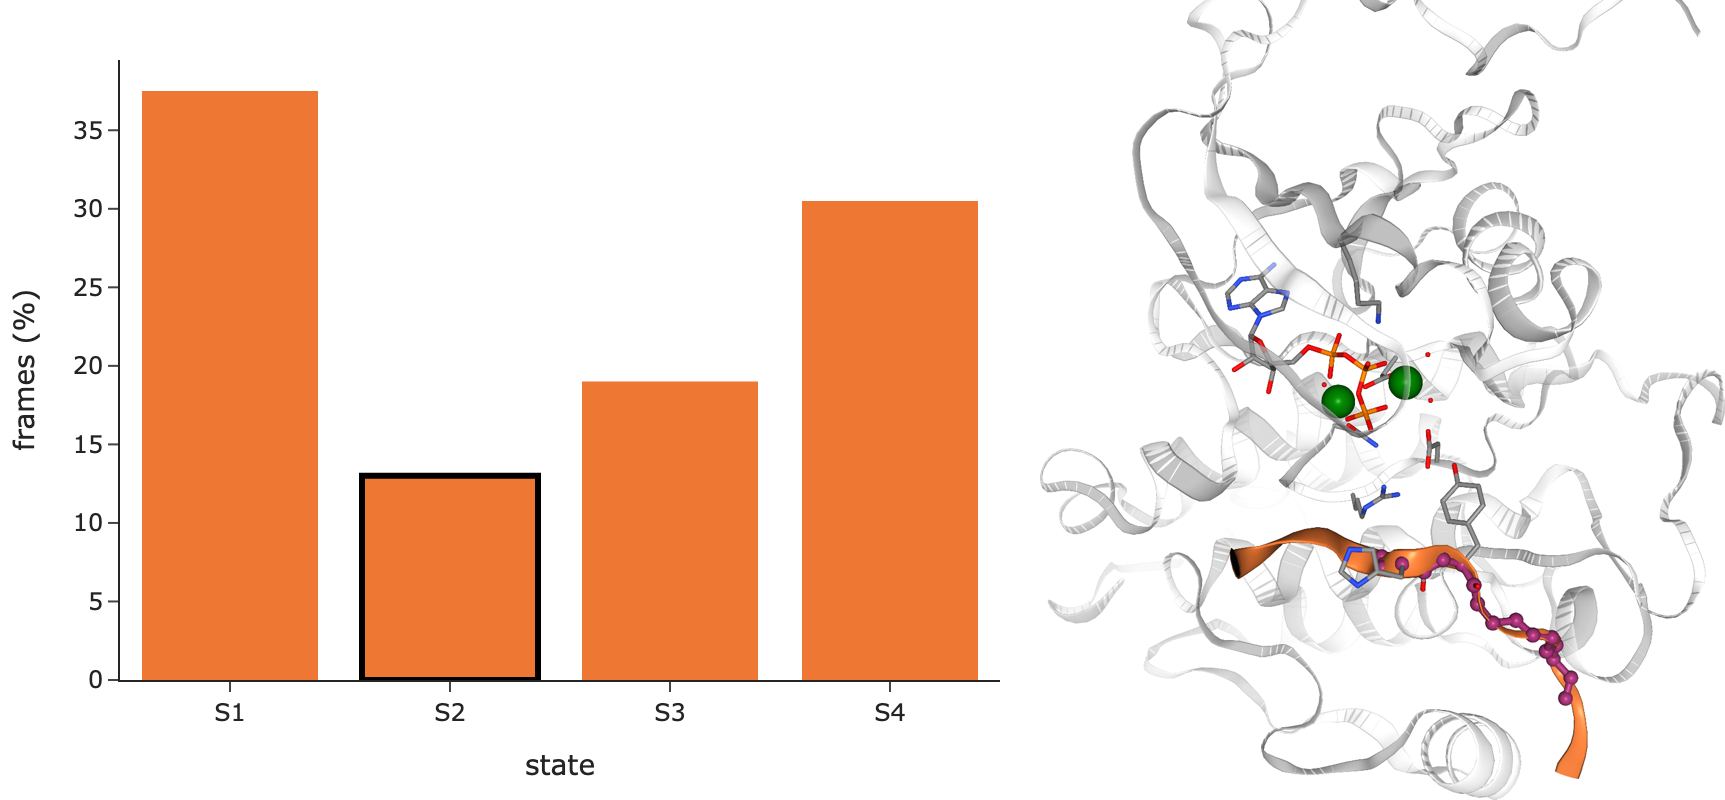

In [18]:
from sklearn.cluster import KMeans

km = KMeans(n_clusters=4, n_init=10, random_state=0).fit(pc)
sizes = np.bincount(km.labels_)
closest = [int(np.argmin(((pc - c) ** 2).sum(axis=1))) for c in km.cluster_centers_]

linked(go.Figure(go.Bar(x=[f"S{i + 1}" for i in range(4)], y=100 * sizes / len(frames),
                        customdata=closest, marker_color=ORANGE))
       .update_layout(xaxis_title="state", yaxis_title="frames (%)"))

## 5. Flexibility

**RMSD time series:** peptide backbone RMSD from the first frame, after fitting on the kinase (how far the peptide
moves relative to the kinase).

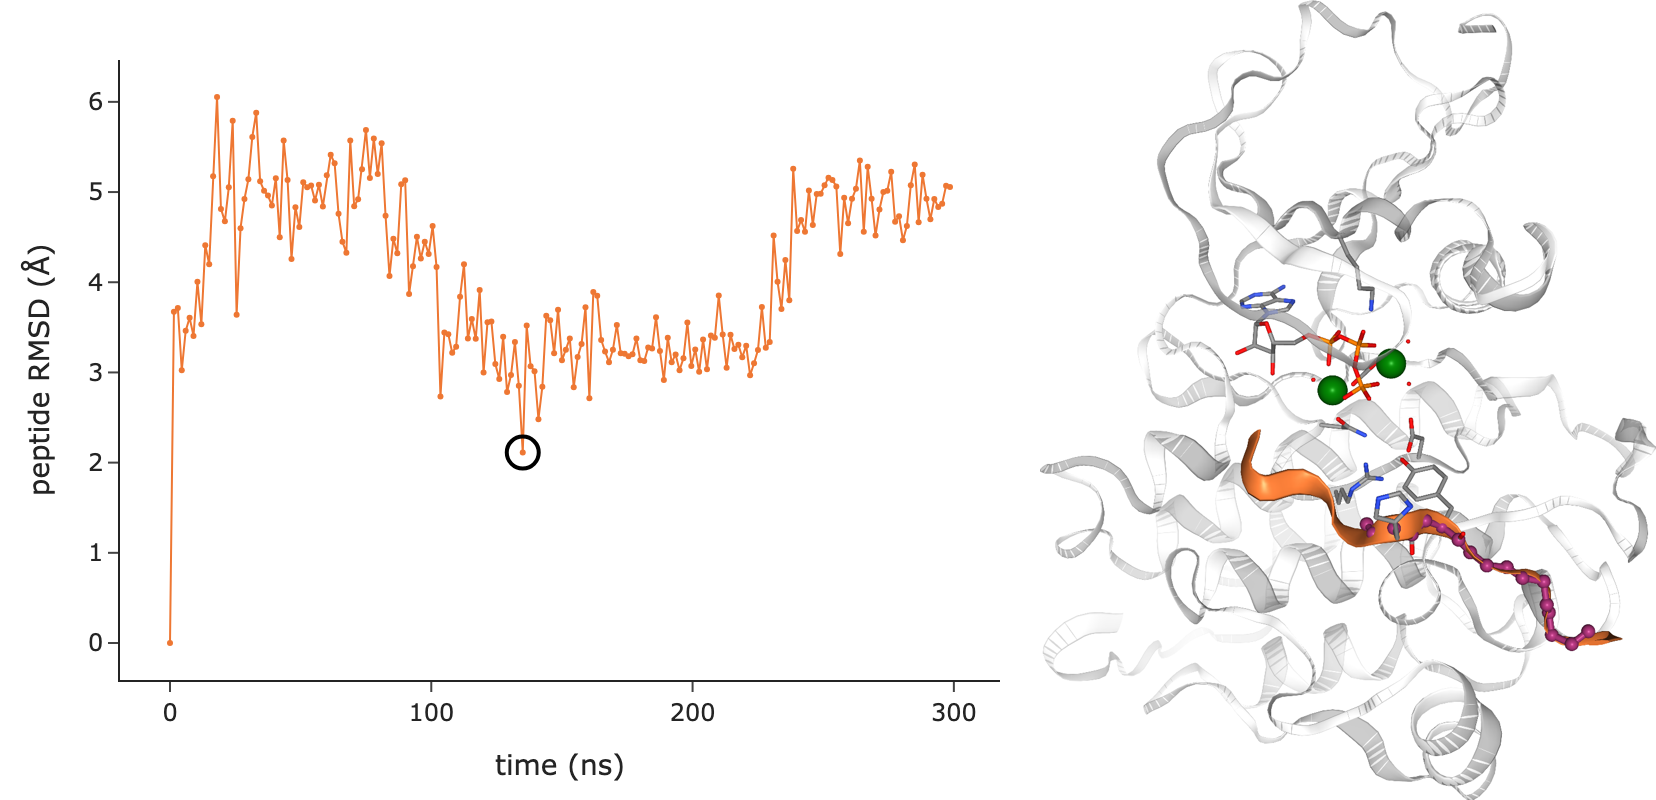

In [19]:
from MDAnalysis.analysis.rms import RMSD, RMSF

rmsd = RMSD(u, ref, select=ca, groupselections=["chainID B and backbone"]).run().results.rmsd[:, 3]

linked(go.Figure(go.Scatter(x=t_ns, y=rmsd, mode="lines+markers", customdata=frames,
                            marker=dict(size=3, color=ORANGE), line=dict(width=1, color=ORANGE)))
       .update_layout(xaxis_title="time (ns)", yaxis_title="peptide RMSD (Å)"))

**Per-residue bar chart:** how much each peptide position moves (Cα RMSF). A click here centers the viewer on that
residue instead of changing the frame.

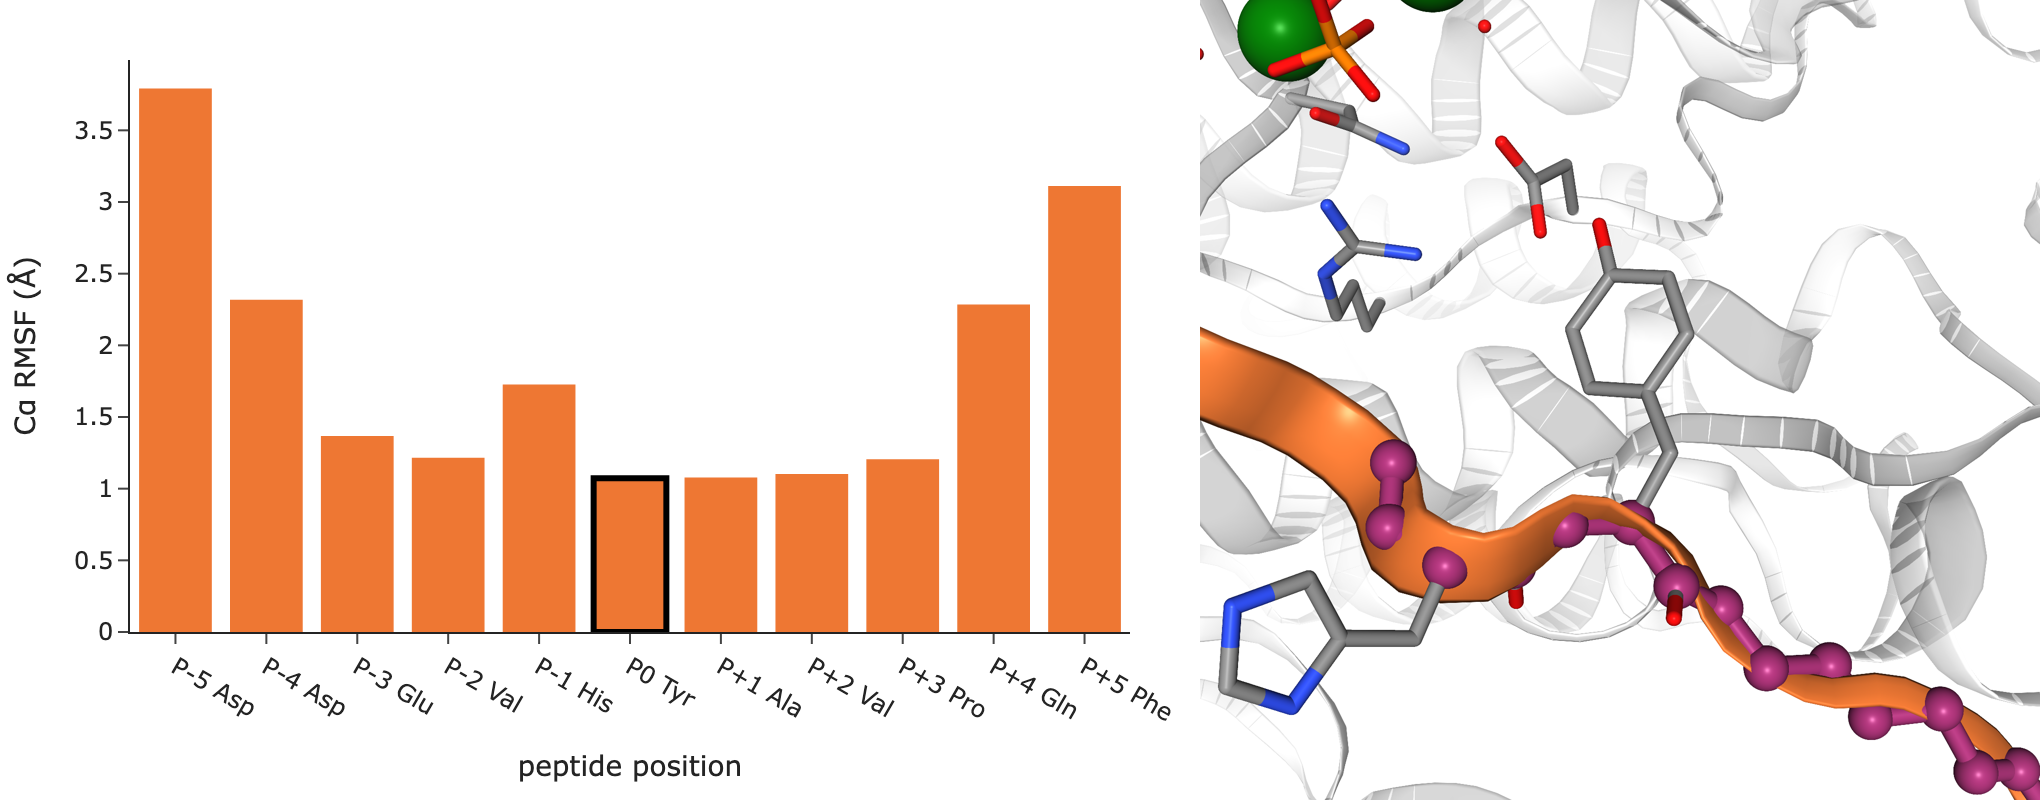

In [21]:
pep = u.select_atoms("chainID B and name CA")
rmsf = RMSF(pep).run().results.rmsf

v, fig = viewer(), go.FigureWidget(go.Bar(x=[label(r) for r in pep.residues], y=rmsf, marker_color=ORANGE))
def click(trace, points, state, v=v, fig=fig):   # keep these even if v, fig are reused
    if points.point_inds:
        mark(fig, trace, points.point_inds[0])
        v.center(f"{pep.residues[points.point_inds[0]].resid}:B")
fig.data[0].on_click(click)
fig.update_layout(width=600, height=400, template="simple_white", xaxis_title="peptide position",
                  yaxis_title="Cα RMSF (Å)", margin=dict(l=60, r=20, t=30, b=50))
panel = Panel(fig, v)

## 6. Contacts

**Heatmap:** fraction of frames in which each peptide residue has a heavy atom within 4.5 Å of each kinase or ATP
residue. Click a cell to see a typical frame of that contact (closest distance nearest its median); click the same
cell again to step through frames spread over the run. The closest atom pair is drawn.

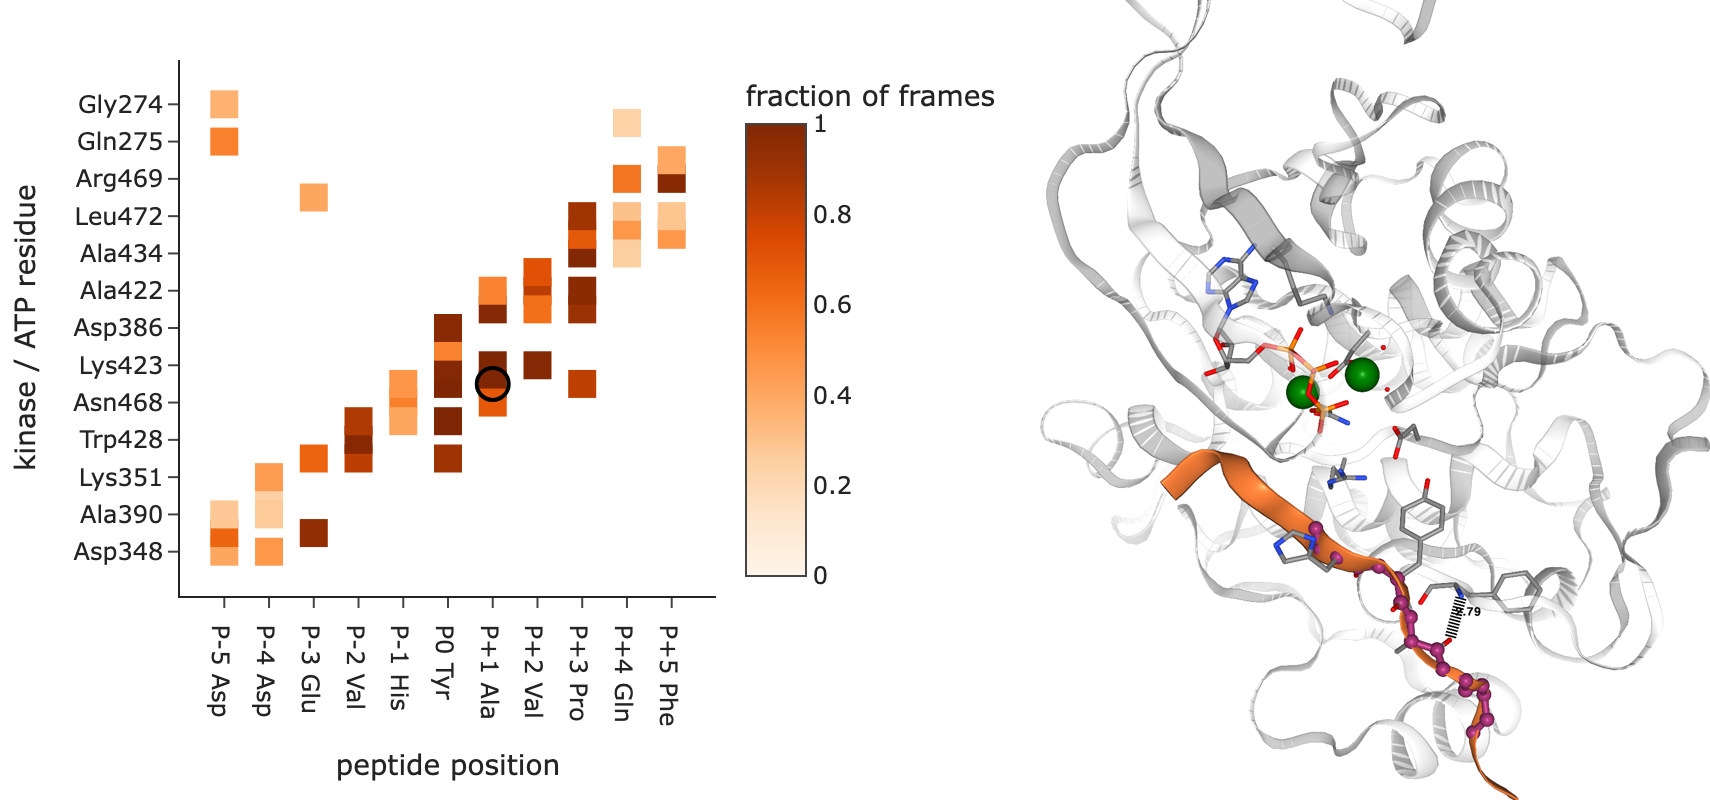

In [22]:
import itertools

pep_res = u.select_atoms("chainID B").residues
partner = u.select_atoms("(chainID A or chainID C) and not name H*")
contact = {}                                   # (peptide residue, partner residue): {frame: closest distance}
for f, ts in enumerate(u.trajectory):
    for r in pep_res:
        idx, d = capped_distance(r.atoms.select_atoms("not name H*").positions, partner.positions,
                                 4.5, box=ts.dimensions)
        for j, dj in zip(idx[:, 1], d):
            fd = contact.setdefault((r.ix, partner[j].resindex), {})
            fd[f] = min(fd.get(f, np.inf), dj)
cells = [(a, b, len(fd) / len(frames), fd) for (a, b), fd in contact.items() if len(fd) > 0.2 * len(frames)]

def closest(a, b, f):
    """Frame f and the closest heavy-atom pair between residues a and b in it."""
    u.trajectory[f]
    A, B = (u.residues[x].atoms.select_atoms("not name H*") for x in (a, b))
    i, j = np.unravel_index(distance_array(A.positions, B.positions, box=u.dimensions).argmin(), (A.n_atoms, B.n_atoms))
    return f, [(A[i].index, B[j].index)]

hits = []                  # each click: the typical frame first, then ~10 frames spread over the contact's frames
for a, b, _, fd in cells:
    fs, d = np.array(list(fd)), np.array(list(fd.values()))
    first = fs[np.abs(d - np.median(d)).argmin()]
    steps = itertools.cycle([first] + [f for f in fs[:: max(1, len(fs) // 10)] if f != first])
    hits.append(lambda a=a, b=b, steps=steps: closest(a, b, next(steps)))

linked(go.Figure(go.Scatter(x=[label(u.residues[c[0]]) for c in cells], y=[label(u.residues[c[1]]) for c in cells],
                            customdata=np.arange(len(cells)), mode="markers",
                            marker=dict(symbol="square", size=14, color=[c[2] for c in cells], colorscale="Oranges",
                                        cmin=0, cmax=1, colorbar=dict(title="fraction of frames")),
                            hovertemplate="%{x} - %{y}<extra></extra>"))
       .update_layout(xaxis=dict(title="peptide position", categoryorder="array",
                                 categoryarray=[label(r) for r in pep_res]),
                      yaxis_title="kinase / ATP residue"), hits)

## Summary

| Plot | Good for | A click… |
|---|---|---|
| Time series | when things happen | goes to that time |
| 2D scatter | two coupled measures | shows that combination |
| Event raster | which bonds or contacts exist, and when | shows that event, drawn |
| UpSet plot of networks | which combinations of bonds occur together | shows a typical frame of that combination |
| Ramachandran / free-energy landscape | states of a flexible region | compares basins |
| Bar chart of clusters | how populated each state is | shows the frame nearest the cluster center |
| Per-residue bars | which residues move most | centers the viewer on that residue |
| Heatmap | which pairs are in contact | typical frame, then more frames on each click |

**The pattern is always the same:** put a frame number (or an index into a list of frames and atoms) in
`customdata`, and in `on_click` set `view.frame` and redraw the highlight.

## Using it on your own system

1. **Files:** point the load cell at your topology and a processed trajectory (PBC removed, strided to a few
   thousand frames at most; every frame the viewer shows is read live from the file).
2. **Chains:** assign `chainIDs` per segment or molecule so selections stay short, or use your own selections.
3. **Labels and style:** replace `label()` and the selections in `viewer()` (`SITE`, `DPCA_ATOMS`), and set
   `ORIENT` to a view you like (see the viewer section).
4. **Metrics:** each example only needs its selections changed. Keep the `customdata` / `hits` part as is.

## Ask Claude to build this for your project

This is roughly what produced this notebook.
```text
Make me a Jupyter notebook of interactive analysis plots for my MD trajectory. Each plot sits next to an nglview
viewer, and clicking a point jumps the viewer to that frame and highlights the atoms behind it (dashed distance
lines, or sticks for the residues involved). Use MDAnalysis, plotly FigureWidget and ipywidgets.

System and files: [e.g. "protein + peptide + ATP, GROMACS md.tpr and md.xtc, PBC removed, 5000 frames"]
What I want to look at: [e.g. key distances, hydrogen bonds, water bridges, backbone conformations, RMSD/RMSF,
contacts]

Start with a minimal example, then one or two plot types per analysis (time series, scatter, event raster,
heatmap, free-energy landscape, ...). Keep the code short with small reusable helpers, and run it to check it works.
```

## Saving pictures for GitHub

GitHub can't run widgets, so on github.com the plots above would be blank. After clicking a point in each plot, run
these two cells (one at a time), then save the notebook. Each plot's output then also holds a picture of the plot and
its viewer as they look now, which GitHub shows instead. The first cell asks every viewer for an image; the second
puts each one next to its plot.

In [27]:
for p in PANELS.values():
    p.v._image_data = ""
    p.v.render_image(trim=True)

In [29]:
saved = 0
for p in PANELS.values():
    if not p.v._image_data:      # not rendered yet: scroll to it, then run both cells again
        continue
    plot = Image.open(io.BytesIO(p.fig.to_image("png", scale=2)))
    mol = Image.open(io.BytesIO(base64.b64decode(p.v._image_data))).convert("RGB")
    mol = mol.resize((round(mol.width * plot.height / mol.height), plot.height))
    both = Image.new("RGB", (plot.width + mol.width, plot.height), "white")
    both.paste(plot, (0, 0))
    both.paste(mol, (plot.width, 0))
    buf = io.BytesIO()
    both.save(buf, "png", optimize=True)
    p.png = base64.b64encode(buf.getvalue()).decode()
    p.handle.update(p)
    saved += 1
print(saved, "of", len(PANELS), "pictures saved; save the notebook to keep them")

13 pictures saved; save the notebook to keep them
